作业：基于 PPO 算法解决 CartPole 与 Pendulum 控制问题（学生实验版）

# 1. 实验简介

本实验要求补全 **Proximal Policy Optimization（PPO）** 算法的核心代码，
分别在 `CartPole-v1`（离散动作）和 `Pendulum-v1`（连续动作）环境中完成训练。

- **环境**：CartPole-v1（小车倒立摆，动作离散）；Pendulum-v1（单摆，动作连续，范围 [-2, 2]）
- **框架**：PyTorch + Gymnasium
- **算法**：PPO-Clip（裁剪策略概率比，限制策略更新幅度）

# 2. 待完成任务（Tasks）

补全代码中标记为 `【待补全代码 1~5】` 的部分：

1. **待补全 1**：计算广义优势估计（GAE）
2. **待补全 2**：实现离散动作策略网络的前向传播
3. **待补全 3**：构建离散动作 PPO 的裁剪目标函数
4. **待补全 4**：计算连续动作策略网络的均值 `mu` 和标准差 `std`
5. **待补全 5**：构建连续动作 PPO 的裁剪目标函数

补全后删除对应的 `raise NotImplementedError(...)`，依次运行各代码单元，
观察两个环境的回合奖励变化，并保留训练曲线。

# 3. 运行环境

使用已配置好 PyTorch、Gymnasium、NumPy、Matplotlib 和 tqdm 的 Python 环境运行。


## 使用说明

1. 将文件名中的学号、学生替换为自己的信息，选择已安装依赖的 Python 内核（本机为 `RL_basic`）。
2. 按任务说明补全五处 `【待补全代码】`。
3. 从头依次运行全部单元，保留两个环境的训练曲线和自检输出。
4. 完成结果分析，再运行最后的评估与 GIF 单元，保留测试结果与两张动图。

### 实验约定

- 使用题目给定的网络与超参数；如作调整，请记录理由与具体设置。
- CartPole 使用模板的 **200 步上限**，训练、评估和 GIF 保持一致。请据此解释奖励，而不要按 500 步上限评价。
- Pendulum 的均值限制在 [-2, 2]，但普通正态分布采样动作仍可能越界，环境会裁剪实际力矩。轨迹中保留原始采样动作来计算正态密度；如修改策略分布，需保证采样和概率计算一致。
- 真实终止与时间截断的价值自举处理已在模板中区分，本实验每次更新只使用一个回合的轨迹。
- 评估和 GIF 使用独立环境及固定测试种子，采用确定性动作；训练仍采用采样动作探索。
- 学生版的曲线、权重、奖励数组、评估数据和 GIF 保存在 `ppo_student_results/`，与已完成版的结果分开保存。
- GIF 会嵌入 Notebook。提交前请保留执行结果，确保动图正常显示。


In [1]:
"""
Proximal Policy Optimization (PPO) —— 离散与连续动作空间版
环境    : CartPole-v1 / Pendulum-v1
框架    : PyTorch + Gymnasium
"""

# ==================== 导入依赖库 ====================
import gymnasium as gym                     # 强化学习环境库
import numpy as np                          # 数值计算、轨迹处理
import matplotlib.pyplot as plt             # 训练曲线绘制
import torch                                # 深度学习框架
import torch.nn as nn                       # 全连接网络等神经网络组件
import torch.nn.functional as F            # 激活函数与均方误差
from torch.distributions import Categorical, Normal  # 离散分布与正态分布
from tqdm.auto import tqdm                 # 训练进度条

from pathlib import Path
from PIL import Image as PILImage
from IPython.display import Image, display
import json
import os

# 小型全连接网络使用 CPU 单线程，减少逐步采样和线程调度开销。
torch.set_num_threads(1)
ARTIFACTS = Path('ppo_student_results')
ARTIFACTS.mkdir(exist_ok=True)

# ==================== 训练辅助函数 ====================
def compute_advantage(gamma, lmbda, td_delta):
    """根据 TD Error 计算 GAE，返回 [T, 1] 的优势张量。"""
    deltas = td_delta.detach().cpu().numpy().reshape(-1)  # [T, 1] -> [T]
    advantages = np.zeros_like(deltas, dtype=np.float32)  # 保存每个时间步的优势
    gae = 0.0                                             # 末尾的后续优势设为 0

    # ==================== 【待补全代码 1】 ====================
    # 任务：从序列末尾反向计算广义优势估计（GAE）。
    # 公式：A_t = δ_t + gamma * lmbda * A_(t+1)
    # 1. 从最后一个时间步开始反向遍历。
    # 2. 更新 gae，并将结果存入 advantages[t]。
    #
    # 从序列末尾向前反向递推：A_t = δ_t + γλ·A_{t+1}
    for t in reversed(range(len(deltas))):
        gae = deltas[t] + gamma * lmbda * gae  # 当前 TD Error + 折扣后的后续优势
        advantages[t] = gae                    # 保存第 t 步的优势
    # ========================================================

    return torch.from_numpy(advantages).view(-1, 1)        # [T, 1]


def moving_average(values, window_size):
    """计算回合奖励的移动平均，返回与原序列等长的数组。"""
    values = np.asarray(values, dtype=np.float64)
    if window_size < 1:
        raise ValueError("window_size 必须大于 0")
    left = (window_size - 1) // 2
    right = window_size // 2
    return np.array([
        values[max(0, i - left): min(len(values), i + right + 1)].mean()
        for i in range(len(values))
    ])


def train_on_policy_agent(env, agent, num_episodes):
    """采集一个回合的轨迹，调用 PPO.update() 更新策略。"""
    return_list = []                                      # 保存每回合的累计奖励
    progress = tqdm(range(num_episodes), desc="Training PPO")

    for episode in progress:
        state, _ = env.reset()                            # 重置环境，获取初始状态
        episode_return = 0.0                              # 当前回合的累计奖励
        transition_dict = {                              # 保存本回合轨迹数据
            'states': [], 'actions': [], 'rewards': [],
            'next_states': [], 'dones': []
        }
        done = False

        while not done:
            action = agent.take_action(state)              # 根据当前策略采样动作
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated                 # 终止或达到时间限制均结束回合
            transition_dict['states'].append(state)       # 当前状态
            transition_dict['actions'].append(action)     # 执行动作
            transition_dict['rewards'].append(reward)      # 即时奖励
            transition_dict['next_states'].append(next_state)
            transition_dict['dones'].append(terminated)    # 超时截断时保留 V(s') 的估计
            episode_return += reward
            state = next_state

        return_list.append(episode_return)                 # 记录回合奖励
        agent.update(transition_dict)                     # 根据本回合数据更新参数
        if (episode + 1) % 10 == 0:
            progress.set_postfix(episode=episode + 1,
                                 return_mean=f"{np.mean(return_list[-10:]):.2f}")
    return return_list


def plot_training_curve(return_list, env_name, window_size):
    """绘制回合奖励和移动平均奖励曲线。"""
    episodes = np.arange(1, len(return_list) + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(episodes, return_list, alpha=0.4, label='Episode Return')
    plt.plot(episodes, moving_average(return_list, window_size),
             label='Moving Average Return')
    plt.xlabel('Episode')
    plt.ylabel('Return')
    plt.title(f'PPO on {env_name}')
    plt.legend()
    plt.grid(True)
    plt.savefig(ARTIFACTS / f'{env_name}_training.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


In [3]:
# ==================== CartPole：离散动作空间 ====================
class PolicyNet(nn.Module):
    """Actor：输入状态，输出各离散动作的概率。"""

    def __init__(self, state_dim, hidden_dim, action_dim):
        super(PolicyNet, self).__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim)        # 状态 -> 隐藏层
        self.fc2 = nn.Linear(hidden_dim, action_dim)       # 隐藏层 -> 动作得分

    def forward(self, x):
        x = F.relu(self.fc1(x))                            # 隐藏层激活

        # ==================== 【待补全代码 2】 ====================
        # 任务：将 self.fc2(x) 的输出转换为动作概率。
        # 提示：使用 F.softmax，沿动作维度（dim=1）进行归一化。
        # 输出形状：[batch_size, action_dim]
        #
        # TODO: 在此补全代码
        # ========================================================
        x=F.softmax(self.fc2(x), dim=1)
        return x

class ValueNet(nn.Module):
    """Critic：输入状态，输出状态价值 V(s)。"""

    def __init__(self, state_dim, hidden_dim):
        super(ValueNet, self).__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim)        # 状态 -> 隐藏层
        self.fc2 = nn.Linear(hidden_dim, 1)                # 隐藏层 -> 状态价值

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return self.fc2(x)                                 # [batch_size, 1]


class PPO:
    """离散动作 PPO：使用 PPO-Clip 更新 Actor 和 Critic。"""

    def __init__(self, state_dim, hidden_dim, action_dim, actor_lr, critic_lr,
                 lmbda, epochs, eps, gamma, device):
        self.actor = PolicyNet(state_dim, hidden_dim, action_dim).to(device)
        self.critic = ValueNet(state_dim, hidden_dim).to(device)
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=actor_lr)
        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=critic_lr)
        self.gamma = gamma                                 # 折扣因子
        self.lmbda = lmbda                                 # GAE 参数
        self.epochs = epochs                               # 每批数据重复更新的次数
        self.eps = eps                                     # PPO 裁剪范围
        self.device = device                               # CPU / GPU

    def take_action(self, state):
        state = torch.as_tensor(np.asarray(state, dtype=np.float32),
                                device=self.device).unsqueeze(0)   # [1, state_dim]
        with torch.no_grad():
            probs = self.actor(state)                      # 获取动作概率
            action_dist = Categorical(probs)              # 构建离散动作分布
            action = action_dist.sample()                 # 按概率采样动作
        return action.item()

    def update(self, transition_dict):
        """计算 TD 目标、GAE 和 PPO-Clip 损失，执行多轮参数更新。"""
        states = torch.as_tensor(np.asarray(transition_dict['states'], dtype=np.float32),
                                 device=self.device)                    # [T, state_dim]
        actions = torch.as_tensor(transition_dict['actions'], dtype=torch.long,
                                  device=self.device).view(-1, 1)       # [T, 1]
        rewards = torch.as_tensor(transition_dict['rewards'], dtype=torch.float32,
                                  device=self.device).view(-1, 1)       # [T, 1]
        next_states = torch.as_tensor(np.asarray(transition_dict['next_states'], dtype=np.float32),
                                      device=self.device)
        dones = torch.as_tensor(transition_dict['dones'], dtype=torch.float32,
                                device=self.device).view(-1, 1)         # [T, 1]

        # ---------- 1) 计算 TD 目标与 GAE ----------
        td_target = rewards + self.gamma * self.critic(next_states) * (1 - dones)
        td_delta = td_target - self.critic(states)         # TD Error：δ_t
        advantage = compute_advantage(self.gamma, self.lmbda,
                                      td_delta).to(self.device)         # [T, 1]

        # ---------- 2) 保存更新前策略的对数概率 ----------
        old_log_probs = torch.log(self.actor(states).gather(1, actions)).detach()

        # ---------- 3) 多轮更新 Actor 与 Critic ----------
        for _ in range(self.epochs):
            log_probs = torch.log(self.actor(states).gather(1, actions))

            # ==================== 【待补全代码 3】 ====================
            # 任务：计算离散动作 PPO-Clip 的 Actor Loss。
            # 1. 利用 log_probs 与 old_log_probs 计算概率比 ratio。
            # 2. 计算未裁剪目标 surr1 = ratio * advantage。
            # 3. 将 ratio 限制在 [1 - self.eps, 1 + self.eps] 内，得到 surr2。
            # 4. 对两个目标逐元素取最小，再取负均值，得到 actor_loss。
            #
            # TODO: 在此补全代码
            # ========================================================
            ratio=torch.exp(log_probs - old_log_probs)
            surr1=ratio*advantage
            surr2=torch.clamp(ratio,1-self.eps,1+self.eps)*advantage
            actor_loss = -torch.min(surr1, surr2).mean()

            critic_loss = F.mse_loss(self.critic(states), td_target.detach())
            self.actor_optimizer.zero_grad()               # 清零 Actor 梯度
            self.critic_optimizer.zero_grad()              # 清零 Critic 梯度
            actor_loss.backward()                          # Actor 反向传播
            critic_loss.backward()                         # Critic 反向传播
            self.actor_optimizer.step()                    # 更新 Actor 参数
            self.critic_optimizer.step()                   # 更新 Critic 参数


Training PPO:   0%|          | 0/500 [00:00<?, ?it/s]

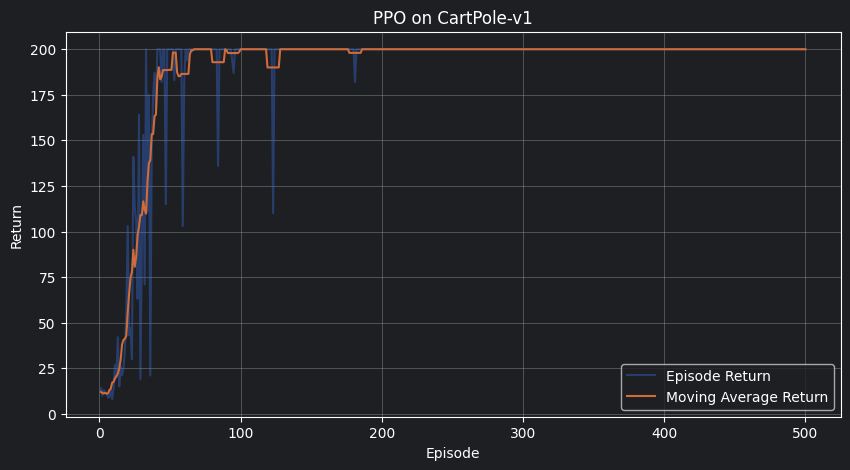

CartPole 最近 10 回合平均奖励：200.00


In [4]:
# ==================== CartPole 训练与可视化 ====================
# ---------- 1) 设置超参数 ----------
actor_lr = 1e-3                                        # Actor 学习率
critic_lr = 1e-2                                       # Critic 学习率
num_episodes = 500                                     # 训练回合数
hidden_dim = 128                                       # 隐藏层维度
gamma = 0.98                                           # 折扣因子 γ
lmbda = 0.95                                           # GAE 参数 λ
epochs = 10                                            # 每批轨迹的更新轮数
eps = 0.2                                              # PPO 截断系数 ε
device = torch.device('cpu')  # 本实验网络较小，CPU 单线程更适合逐步采样

# ---------- 2) 初始化环境与智能体 ----------
env_name = 'CartPole-v1'
env = gym.make(env_name, max_episode_steps=200)        # 对齐原示例的 200 步上限
env.reset(seed=0)                                      # 设置环境随机种子
env.action_space.seed(0)
np.random.seed(0)
torch.manual_seed(0)
state_dim = env.observation_space.shape[0]             # 状态维度：4
action_dim = env.action_space.n                         # 动作数：2
agent = PPO(state_dim, hidden_dim, action_dim, actor_lr, critic_lr,
            lmbda, epochs, eps, gamma, device)

# ---------- 3) 训练并绘制奖励曲线 ----------
cartpole_returns = train_on_policy_agent(env, agent, num_episodes)
env.close()
plot_training_curve(cartpole_returns, env_name, window_size=9)
print(f'CartPole 最近 10 回合平均奖励：{np.mean(cartpole_returns[-10:]):.2f}')

# 分别保留智能体，供末尾评估和 GIF 使用。
cartpole_agent = agent
torch.save({'actor': agent.actor.state_dict(), 'critic': agent.critic.state_dict()},
           ARTIFACTS / 'cartpole_model.pt')
np.save(ARTIFACTS / 'cartpole_returns.npy', cartpole_returns)


In [5]:
# ==================== Pendulum：连续动作空间 ====================
class PolicyNetContinuous(nn.Module):
    """Actor：输入状态，输出正态分布的均值和标准差。"""

    def __init__(self, state_dim, hidden_dim, action_dim):
        super(PolicyNetContinuous, self).__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim)         # 状态 -> 隐藏层
        self.fc_mu = nn.Linear(hidden_dim, action_dim)      # 均值输出层
        self.fc_std = nn.Linear(hidden_dim, action_dim)     # 标准差输出层

    def forward(self, x):
        x = F.relu(self.fc1(x))

        # ==================== 【待补全代码 4】 ====================
        # 任务：根据隐藏层输出计算正态分布参数 mu 与 std。
        # 1. mu：对 self.fc_mu(x) 使用 torch.tanh，再乘以 2.0，映射到 [-2, 2]。
        # 2. std：对 self.fc_std(x) 使用 F.softplus，并加 1e-5 保证标准差为正。
        #
        # TODO: 在此补全代码
        # ========================================================
        mu=torch.tanh(self.fc_mu(x))*2.0
        std=F.softplus(self.fc_std(x))+1e-5
        return mu, std                                     # 两个张量均为 [batch_size, action_dim]


class PPOContinuous:
    """连续动作 PPO：使用正态分布定义策略。"""

    def __init__(self, state_dim, hidden_dim, action_dim, actor_lr, critic_lr,
                 lmbda, epochs, eps, gamma, device):
        self.actor = PolicyNetContinuous(state_dim, hidden_dim, action_dim).to(device)
        self.critic = ValueNet(state_dim, hidden_dim).to(device)
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=actor_lr)
        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=critic_lr)
        self.gamma = gamma
        self.lmbda = lmbda
        self.epochs = epochs
        self.eps = eps
        self.device = device

    def take_action(self, state):
        state = torch.as_tensor(np.asarray(state, dtype=np.float32),
                                device=self.device).unsqueeze(0)
        with torch.no_grad():
            mu, std = self.actor(state)                     # 输出正态分布参数
            action_dist = Normal(mu, std)                  # N(mu, std^2)
            action = action_dist.sample()                  # 从正态分布采样动作
        return action.cpu().numpy()[0]                     # [action_dim]，交给环境执行

    def update(self, transition_dict):
        """连续动作的 PPO-Clip 参数更新。"""
        states = torch.as_tensor(np.asarray(transition_dict['states'], dtype=np.float32),
                                 device=self.device)
        actions = torch.as_tensor(np.asarray(transition_dict['actions'], dtype=np.float32),
                                  device=self.device)                    # [T, action_dim]
        rewards = torch.as_tensor(transition_dict['rewards'], dtype=torch.float32,
                                  device=self.device).view(-1, 1)
        next_states = torch.as_tensor(np.asarray(transition_dict['next_states'], dtype=np.float32),
                                      device=self.device)
        dones = torch.as_tensor(transition_dict['dones'], dtype=torch.float32,
                                device=self.device).view(-1, 1)

        # ---------- 1) 计算 TD 目标与 GAE ----------
        rewards = (rewards + 8.0) / 8.0                      # 与原示例一致的奖励变换
        td_target = rewards + self.gamma * self.critic(next_states) * (1 - dones)
        td_delta = td_target - self.critic(states)
        advantage = compute_advantage(self.gamma, self.lmbda,
                                      td_delta).to(self.device)

        # ---------- 2) 固定旧策略的对数概率 ----------
        with torch.no_grad():
            old_mu, old_std = self.actor(states)
            old_dist = Normal(old_mu, old_std)
            old_log_probs = old_dist.log_prob(actions).sum(dim=1, keepdim=True)

        # ---------- 3) PPO-Clip 多轮更新 ----------
        for _ in range(self.epochs):
            mu, std = self.actor(states)
            action_dist = Normal(mu, std)                   # 当前策略动作分布

            # ==================== 【待补全代码 5】 ====================
            # 任务：计算连续动作 PPO-Clip 的 Actor Loss。
            # 1. 使用 action_dist.log_prob(actions) 计算新策略动作对数概率。
            #    按动作维求和，保持 log_probs 的形状为 [T, 1]。
            # 2. 利用 log_probs 和 old_log_probs 计算概率比 ratio。
            # 3. 计算未裁剪目标 surr1 与裁剪目标 surr2。
            # 4. 对两个目标逐元素取最小，再取负均值，得到 actor_loss。
            #
            # TODO: 在此补全代码
            # ========================================================
            log_probs=action_dist.log_prob(actions).sum(dim=1,keepdim=True)
            ratio=torch.exp(log_probs - old_log_probs)
            surr1=ratio*advantage
            surr2=torch.clamp(ratio,1.0-self.eps,1.0+self.eps)*advantage
            actor_loss=-torch.min(surr1,surr2).mean()


            critic_loss = F.mse_loss(self.critic(states), td_target.detach())
            self.actor_optimizer.zero_grad()
            self.critic_optimizer.zero_grad()
            actor_loss.backward()
            critic_loss.backward()
            self.actor_optimizer.step()
            self.critic_optimizer.step()


Training PPO:   0%|          | 0/2000 [00:00<?, ?it/s]

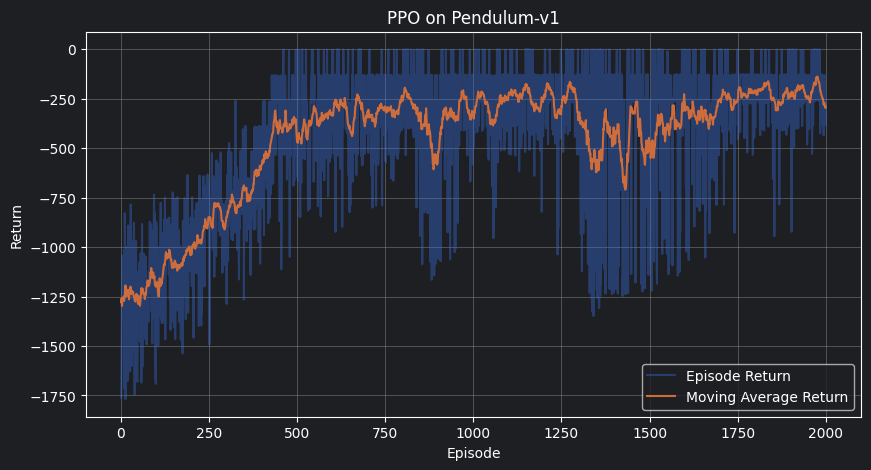

Pendulum 最近 10 回合平均奖励：-305.09


In [6]:
# ==================== Pendulum 训练与可视化 ====================
# ---------- 1) 设置超参数 ----------
actor_lr = 1e-4                                        # Actor 学习率
critic_lr = 5e-3                                       # Critic 学习率
num_episodes = 2000                                    # 训练回合数
hidden_dim = 128                                       # 隐藏层维度
gamma = 0.9                                            # 折扣因子 γ
lmbda = 0.9                                            # GAE 参数 λ
epochs = 10
eps = 0.2
device = torch.device('cpu')  # 本实验网络较小，CPU 单线程更适合逐步采样

# ---------- 2) 初始化环境与智能体 ----------
env_name = 'Pendulum-v1'
env = gym.make(env_name)
env.reset(seed=0)
env.action_space.seed(0)
np.random.seed(0)
torch.manual_seed(0)
state_dim = env.observation_space.shape[0]             # 状态维度：3
action_dim = env.action_space.shape[0]                 # 连续动作维度：1
agent = PPOContinuous(state_dim, hidden_dim, action_dim, actor_lr, critic_lr,
                      lmbda, epochs, eps, gamma, device)

# ---------- 3) 训练并绘制奖励曲线 ----------
pendulum_returns = train_on_policy_agent(env, agent, num_episodes)
env.close()
plot_training_curve(pendulum_returns, env_name, window_size=21)
print(f'Pendulum 最近 10 回合平均奖励：{np.mean(pendulum_returns[-10:]):.2f}')

# 分别保留智能体，供末尾评估和 GIF 使用。
pendulum_agent = agent
torch.save({'actor': agent.actor.state_dict(), 'critic': agent.critic.state_dict()},
           ARTIFACTS / 'pendulum_model.pt')
np.save(ARTIFACTS / 'pendulum_returns.npy', pendulum_returns)


## 独立评估与模型效果 GIF

用测试种子 100～109 评估训练后策略与随机策略；GIF 固定展示种子 100 的完整回合，按环境原始帧率播放。CartPole 奖励越接近 200 越好，Pendulum 奖励越接近 0 越好。

CartPole-v1: 训练后 200.00 ± 0.00, 范围 [200.00, 200.00]; 随机策略 30.80


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


CartPole-v1 | seed=100 | return=200.00 | steps=200 | ppo_student_results/cartpole.gif


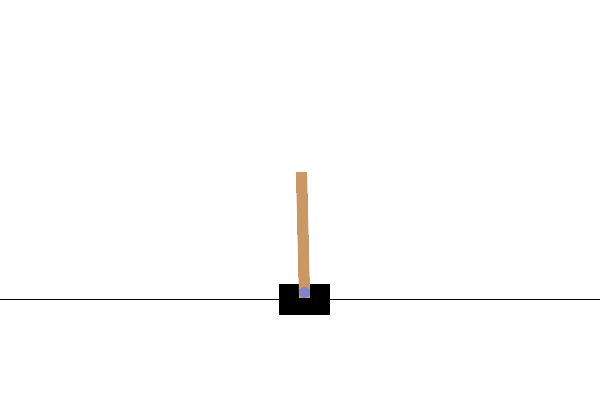

Pendulum-v1: 训练后 -351.77 ± 240.34, 范围 [-806.69, -129.39]; 随机策略 -1271.00
Pendulum-v1 | seed=100 | return=-264.55 | steps=200 | ppo_student_results/pendulum.gif


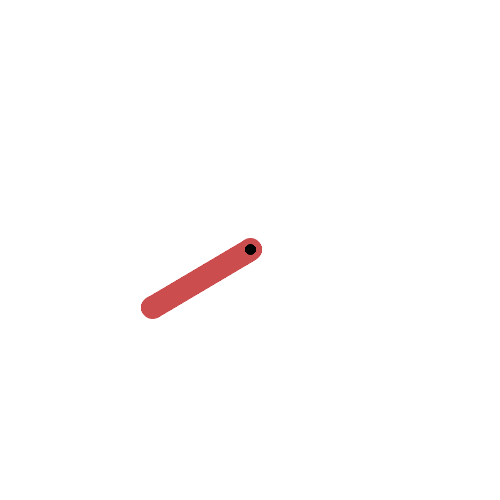

In [7]:
def evaluation_action(agent, state):
    state = torch.as_tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
    with torch.no_grad():
        if isinstance(agent, PPOContinuous):
            mu, _ = agent.actor(state)
            return mu.cpu().numpy()[0]
        return agent.actor(state).argmax(dim=1).item()


def make_demo_env(env_name, render=False):
    kwargs = {'render_mode': 'rgb_array'} if render else {}
    if env_name == 'CartPole-v1':
        kwargs['max_episode_steps'] = 200
    return gym.make(env_name, **kwargs)


def evaluate(agent, env_name, random_policy=False):
    test_env = make_demo_env(env_name)
    scores = []
    try:
        for seed in range(100, 110):
            state, _ = test_env.reset(seed=seed)
            test_env.action_space.seed(seed)
            total = 0.0
            while True:
                action = test_env.action_space.sample() if random_policy else evaluation_action(agent, state)
                state, reward, terminated, truncated, _ = test_env.step(action)
                total += reward
                if terminated or truncated:
                    break
            scores.append(total)
    finally:
        test_env.close()
    return scores


def save_policy_gif(agent, env_name, filename, seed=100):
    os.environ.setdefault('SDL_VIDEODRIVER', 'dummy')
    demo_env = make_demo_env(env_name, render=True)
    frames = []
    total = 0.0
    try:
        state, _ = demo_env.reset(seed=seed)
        frames.append(PILImage.fromarray(demo_env.render()))
        while True:
            state, reward, terminated, truncated, _ = demo_env.step(evaluation_action(agent, state))
            total += reward
            frames.append(PILImage.fromarray(demo_env.render()))
            if terminated or truncated:
                break
        # GIF 的时间精度为 10 ms，取最接近原帧率的帧时长。
        duration = max(10, round(1000 / demo_env.metadata.get('render_fps', 30) / 10) * 10)
        path = ARTIFACTS / filename
        frames[0].save(path, save_all=True, append_images=frames[1:],
                       duration=duration, loop=0, optimize=False)
    finally:
        demo_env.close()
    print(f'{env_name} | seed={seed} | return={total:.2f} | steps={len(frames)-1} | {path}')
    display(Image(data=path.read_bytes(), format='gif'))
    return {'return': total, 'steps': len(frames) - 1, 'seed': seed}


evaluation_results = {}
for env_name, trained_agent, filename in [
    ('CartPole-v1', cartpole_agent, 'cartpole.gif'),
    ('Pendulum-v1', pendulum_agent, 'pendulum.gif'),
]:
    scores = evaluate(trained_agent, env_name)
    random_scores = evaluate(trained_agent, env_name, random_policy=True)
    print(f'{env_name}: 训练后 {np.mean(scores):.2f} ± {np.std(scores):.2f}, '
          f'范围 [{min(scores):.2f}, {max(scores):.2f}]; 随机策略 {np.mean(random_scores):.2f}')
    demo = save_policy_gif(trained_agent, env_name, filename)
    evaluation_results[env_name] = {'trained_returns': scores, 'random_returns': random_scores, 'demo': demo}
_ = (ARTIFACTS / 'evaluation.json').write_text(json.dumps(evaluation_results, indent=2), encoding='utf-8')
